# Start-up — heat-up recipe, rates, gases and timing (all 39 days)

**Start-up** is the heat-up from a cold or warm stack until Hot standby (`../01_docs/operational-modes.md` §1). It only
follows a Shut-down (or Idle on 2025-10-30, the first file). Re-heats and cool-backs of a stack that is already hot,
with no load, are **not** Start-up: they are the separate stage **Thermal adjustment**, analysed in
[`thermal_adjustment_analysis.ipynb`](thermal_adjustment_analysis.ipynb). The switch from forming gas to natural gas
before load is covered there and in the Hot standby *Pre-load* minutes.

The episodes split into two sub-types:

| Sub-type | Test | Typical |
|---|---|---|
| **Cold start-up** | starts at ≤ 100 °C | room temperature → ~500 °C hold or ~570 °C Hot standby, 12–15 h |
| **Warm restart** | starts above 100 °C | a stack still warm from an earlier run, heated again |

One heat-up contains a plant-off pause: on **2026-03-17** the plant stopped at 20:08 at 188 °C and restarted on
03-18 at 07:10 at 167 °C (≈ −2 °C/h). The pause is the operation *Heat-up interrupted (plant off)* inside the one
Start-up `20260317_1456_Start-up` (user decision 2026-10-14). Its 11 h are kept out of the rate statistics and
reported separately in the durations (`pause_h`, `heating_h`).

This notebook covers:

1. **Inventory**: every Start-up episode, its sub-type, what came before and after, and whether it reached Hot standby.
2. **What the hours contain**: minutes per operation.
3. **Heat-up rate**: band rates, the 120 °C/h limit, the hottest thermocouple, holds and pauses.
4. **Heater recipe**: EAPH setpoint steps and ramp, heater power and energy, how far the stack lags the heater.
5. **Thermal gradient**: spread across the stack thermocouples and the inlet-side lead.
6. **Gas and air sequence**: when air, forming gas (N₂ + H₂) and natural gas come on.
7. **Timings**: durations and clock times.
8. **Signal levels by temperature band** (input for synthetic data).

**Data:** stage and operation labels and episodes come from `04_synthetic_data/library/` (`traces_1min.parquet`,
`episodes.csv`), rebuilt from `operating_states.py` on 2026-10-14. The extra signals are read from
`02_data/downsampled/*_10s.parquet` by `stage_signals.py` and averaged to 1 min. Tables and figures are saved to
`startup/`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, "scripts")  # helper modules live in 03_data_analysis/scripts/
import operating_states as ops
import stage_signals as ss

pd.set_option("display.max_rows", 120)
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 30)

OUT = Path("startup")
OUT.mkdir(exist_ok=True)
LIMIT = 120.0  # °C/h, heat-up limit (Elcogen p.18, p.20–21)
COLD_MAX_C = 100.0  # a start-up from at or below this is a cold start-up
SUB_COLORS = {"Cold start-up": "#2a78d6", "Warm restart": "#eb6834"}
plt.rcParams.update(
    {
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.alpha": 0.25,
        "lines.linewidth": 1.4,
        "font.size": 9,
    }
)

## 1. Load labels, signals and episodes

`stage_signals.load()` joins the library labels with flows, BOP temperatures, the EAPH outlet controller (`TIRC 2.06`)
and the 36 stack thermocouples. The thermocouple spread is recomputed robustly: `TIR_4_6_25` reads ambient in every
file and is dropped, and any thermocouple more than 150 K from the module median in a minute is ignored
(`TIR_4_6_19` on 2026-03-13). The library's own min/max keeps `TIR_4_6_25` on days that start cold, which makes the
spread jump to ~450 K during a heat-up.

In [2]:
d = ss.load()
e = ss.neighbours(ss.episodes())
su = e[e.stage == "Start-up"].copy()
assert not su.operations.str.contains(
    "|".join(ops.REHEAT_OPS + ops.COOL_BACK_OPS), regex=False
).any()
su["subtype"] = np.where(su.T_start_C <= COLD_MAX_C, "Cold start-up", "Warm restart")
su["outcome"] = np.select(
    [
        su.next_stage.isin(["Hot standby", "Part load"]),
        su.next_stage == "file edge",
        su.next_stage == "Start-up",
    ],
    ["reached " + su.next_stage, "cut at file edge", "continues after logger gap"],
    default="stopped → " + su.next_stage,
)
d["subtype"] = d.episode_id.map(su.set_index("episode_id").subtype)
s = d[d.stage == "Start-up"]
# T_start / T_end from the cleaned trace (the library value can sit on a logger-dropout
# minute)
su["T_start_C"] = su.episode_id.map(s.groupby("episode_id").T_stack_C.first())
su["T_end_C"] = su.episode_id.map(s.groupby("episode_id").T_stack_C.last())
su["warming_K"] = (
    su.episode_id.map(s.groupby("episode_id").T_stack_C.max()) - su.T_start_C
)
# plant-off pause inside a heat-up (2026-03-17/18): kept apart from the heating time
paused = s.operation == ops.PAUSED
su["pause_h"] = (
    su.episode_id.map(paused.groupby(s.episode_id).sum() / 60).fillna(0).round(2)
)
su["heating_h"] = (su.duration_h - su.pause_h).round(2)
su["gap_before_h"] = (su.gap_before_min / 60).round(1)
# "ramp minutes": heater on and the stack really warming; holds and the false start stay
# out of rate statistics
ramp = (s.operation == "Heat-up (EAPH on)") & (s.dTdt_C_per_h > ops.DTDT_HEAT)
print(
    f"{len(s):,} Start-up minutes ({len(s) / 60:.0f} h, {len(s) / len(d):.0%} of "
    f"logged time) in {len(su)} episodes; "
    f"{int(s.logger_dropout.sum())} logger-dropout minutes blanked"
)
su.subtype.value_counts().to_frame("episodes")

9,568 Start-up minutes (159 h, 17% of logged time) in 15 episodes; 1 logger-dropout minutes blanked


,episodes
subtype,
Cold start-up,8
Warm restart,7


## 2. Inventory of Start-up episodes

`outcome` is the stage that follows. *Stopped* means the heat-up ended without reaching Hot standby (the stack then
cools: Idle or Shut-down). `ends_in_trip` marks an episode that ended in a safety event (from the library's fault
flags). `pause_h` is the plant-off pause inside the heat-up, `heating_h` the duration without it, and
`gap_before_h` a logger gap (missing data) right before the episode.

In [3]:
inv = su[
    [
        "episode_id",
        "subtype",
        "start",
        "end",
        "duration_h",
        "pause_h",
        "heating_h",
        "T_start_C",
        "T_end_C",
        "warming_K",
        "prev_stage",
        "gap_before_h",
        "outcome",
        "operations",
        "complete",
        "ends_in_trip",
        "fault_events",
    ]
].copy()
inv[inv.select_dtypes("number").columns] = inv.select_dtypes("number").round(2)
inv.to_csv(OUT / "episodes.csv", index=False)
inv.drop(columns=["fault_events"])

,episode_id,subtype,start,end,duration_h,pause_h,heating_h,T_start_C,T_end_C,warming_K,prev_stage,gap_before_h,outcome,operations,complete,ends_in_trip
1,20251030_1129_Start-up,Warm restart,2025-10-30 11:29:00,2025-10-30 14:31:00,3.03,0.00,3.03,139.48,215.53,78.70,Idle,0.0,stopped → Idle,"Air flow start (purge, heater off) > Heat-up (...",True,False
4,20251113_1047_Start-up,Cold start-up,2025-11-13 10:47:00,2025-11-13 21:32:00,10.75,0.00,10.75,10.11,471.65,468.78,Shut-down,0.0,stopped → Shut-down,Heat-up (EAPH on) > Heat-up paused (heater off...,True,False
7,20260130_1010_Start-up,Cold start-up,2026-01-30 10:10:00,2026-01-30 19:10:00,9.00,0.00,9.00,4.10,240.49,241.92,Shut-down,0.0,stopped → Shut-down,Heat-up (EAPH on) > Heat-up paused (heater off),True,False
9,20260131_0809_Start-up,Warm restart,2026-01-31 08:09:00,2026-01-31 17:47:00,9.63,0.00,9.63,176.02,571.60,395.58,Shut-down,0.0,reached Hot standby,Heat-up (EAPH on) > Final heat-up to Hot standby,True,False
16,20260206_1327_Start-up,Cold start-up,2026-02-06 13:27:00,2026-02-07 00:00:00,10.55,0.00,10.55,45.29,42.79,0.01,Shut-down,0.0,cut at file edge,Heat-up (EAPH on),False,False
18,20260213_1432_Start-up,Cold start-up,2026-02-13 14:32:00,2026-02-14 02:58:00,12.43,0.00,12.43,14.54,495.43,480.89,Shut-down,0.0,reached Hot standby,Heat-up (EAPH on),True,False
21,20260217_1656_Start-up,Warm restart,2026-02-17 16:56:00,2026-02-18 02:19:00,9.38,0.00,9.38,191.72,495.25,303.53,Shut-down,0.0,reached Hot standby,Heat-up (EAPH on),True,False
27,20260301_0905_Start-up,Cold start-up,2026-03-01 09:05:00,2026-03-01 21:43:00,12.63,0.00,12.63,27.53,494.09,466.56,Shut-down,0.0,reached Hot standby,"Air flow start (purge, heater off) > Heat-up (...",True,False
37,20260312_1029_Start-up,Cold start-up,2026-03-12 10:29:00,2026-03-13 01:13:00,14.73,0.00,14.73,28.39,566.64,538.26,Shut-down,0.0,reached Hot standby,"Air flow start (purge, heater off) > Heat-up (...",True,False
45,20260317_1456_Start-up,Cold start-up,2026-03-17 14:56:00,2026-03-18 17:27:00,26.52,11.05,15.47,57.69,566.77,509.09,Shut-down,4.5,reached Hot standby,"Air flow start (purge, heater off) > Heat-up (...",True,False


In [4]:
print("outcome by sub-type")
pd.crosstab(su.subtype, su.outcome)

outcome by sub-type


outcome,continues after logger gap,cut at file edge,reached Hot standby,stopped → Idle,stopped → Shut-down
subtype,,,,,
Cold start-up,0,1,5,0,2
Warm restart,1,0,5,1,0


## 3. What the Start-up hours contain

Minutes per operation and sub-type. The operations come from `operating_states.py`: *Air flow start* is the
purge before the heater; *Heat-up (EAPH on)* the main ramp; *Final heat-up* and *Slow heat-up* the slow approach to
Hot standby above 550 °C (5–10 °C/h); *Intermediate hold* a short (< 6 h) stop at ~510 °C; *Heat-up paused (heater
off)* a heater pause of up to 3 h; *Heat-up interrupted (plant off)* the overnight plant-off pause of 2026-03-17/18.

In [5]:
opm = (
    s.groupby(["operation", "subtype"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=list(SUB_COLORS), fill_value=0)
)
opm["hours"] = (opm.sum(axis=1) / 60).round(1)
opm = opm.sort_values("hours", ascending=False)
opm.to_csv(OUT / "operations.csv")
opm

subtype,Cold start-up,Warm restart,hours
operation,,,
Heat-up (EAPH on),5328,2354,128.0
Heat-up interrupted (plant off),663,0,11.0
Final heat-up to Hot standby,93,315,6.8
Slow heat-up,135,154,4.8
"Air flow start (purge, heater off)",149,58,3.4
Heat-up paused (heater off),123,0,2.0
Temperature dip during heat-up (heater on),0,106,1.8
Intermediate hold (~510 °C),41,49,1.5


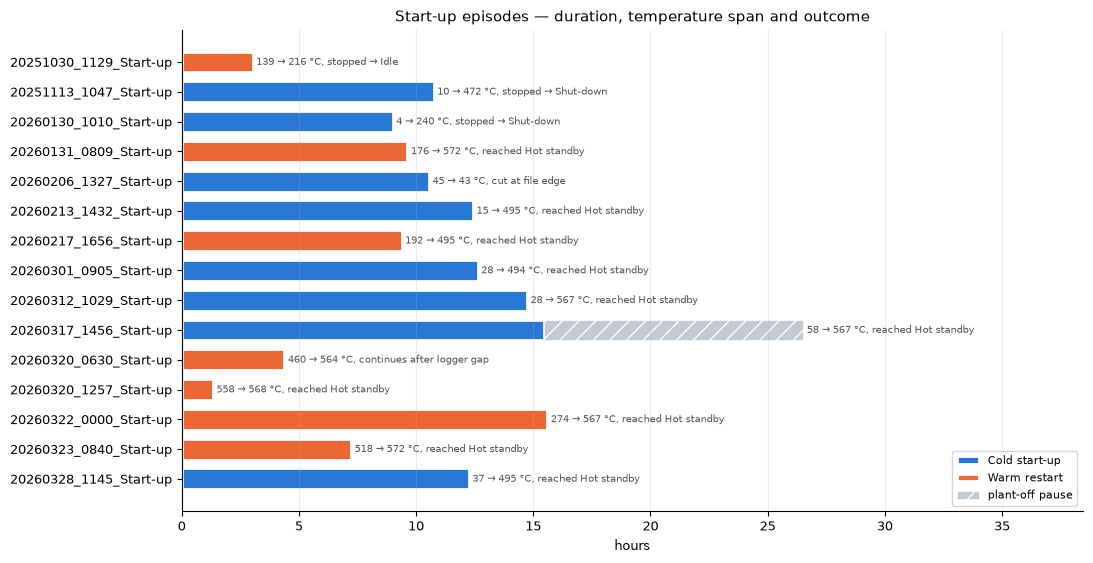

In [6]:
fig, ax = plt.subplots(figsize=(11, 0.28 * len(su) + 1.5))
y_ep = np.arange(len(su))
for n, col in SUB_COLORS.items():
    m = (su.subtype == n).values
    ax.barh(
        y_ep[m],
        su.heating_h[m],
        color=col,
        label=n,
        height=0.7,
        edgecolor="white",
        linewidth=2,
    )
ax.set_yticks(y_ep, su.episode_id)
ax.barh(
    y_ep,
    su.pause_h,
    left=su.heating_h,
    color="#c3c9d0",
    hatch="//",
    label="plant-off pause",
    height=0.7,
    edgecolor="white",
    linewidth=0.5,
)
for y, (o, t0, t1, w) in enumerate(
    zip(su.outcome, su.T_start_C, su.T_end_C, su.duration_h)
):
    ax.text(
        w + 0.15,
        y,
        f"{t0:.0f} → {t1:.0f} °C, {o}",
        va="center",
        fontsize=7,
        color="#555",
    )
ax.invert_yaxis()
ax.set_xlabel("hours")
ax.grid(axis="y", visible=False)
ax.set_xlim(0, su.duration_h.max() * 1.45)
ax.set_title("Start-up episodes — duration, temperature span and outcome")
ax.legend(loc="lower right", fontsize=8)
fig.tight_layout()
fig.savefig(OUT / "episodes_overview.png", dpi=130)
plt.show()

## 4. Heat-up rate

### 4.1 Band rates

Time between the first upward crossings of each band by the stack median (as in `operational-modes.md` §4.2), for
cold start-ups and warm restarts. A blank means the episode did not cross that band from below. A band whose
crossing straddles the 11 h plant-off pause of 2026-03-17/18 is also blanked: the stack had just passed 200 °C, cooled
to 167 °C overnight and was re-warmed on 03-18, so its 200→300 °C time is not a heating rate.

In [7]:
BANDS = [(50, 100), (100, 200), (200, 300), (300, 400), (400, 500), (500, 550)]
heat = su
rows = []
for _, r in heat.iterrows():
    g = d[d.episode_id == r.episode_id]
    T = g.T_stack_C.interpolate(limit=60)
    row = ss.band_rates(T, g.index, BANDS)
    p = (g.operation == ops.PAUSED).values
    for lo, hi in BANDS:  # blank a band that straddles a plant-off pause
        a, b = np.argmax(T.values >= lo), np.argmax(T.values >= hi)
        if p[a : b + 1].any():
            row[f"{lo}->{hi}"] = np.nan
    rows.append({"episode_id": r.episode_id, "subtype": r.subtype, **row})
br = pd.DataFrame(rows).set_index("episode_id")
br.loc["median (all)"] = br.drop(columns="subtype").median()
br.round(1).to_csv(OUT / "band_rates.csv")
br.round(1)

,subtype,50->100,100->200,200->300,300->400,400->500,500->550
episode_id,,,,,,,
20251030_1129_Start-up,Warm restart,NaN,NaN,NaN,NaN,NaN,NaN
20251113_1047_Start-up,Cold start-up,78.9,35.9,36.1,75.9,NaN,NaN
20260130_1010_Start-up,Cold start-up,49.2,20.8,NaN,NaN,NaN,NaN
20260131_0809_Start-up,Warm restart,NaN,NaN,49.6,53.1,51.7,40.0
20260206_1327_Start-up,Cold start-up,NaN,NaN,NaN,NaN,NaN,NaN
20260213_1432_Start-up,Cold start-up,47.6,50.8,55.0,56.6,NaN,NaN
20260217_1656_Start-up,Warm restart,NaN,NaN,45.8,51.3,NaN,NaN
20260301_0905_Start-up,Cold start-up,46.2,50.4,54.5,55.6,NaN,NaN
20260312_1029_Start-up,Cold start-up,46.2,50.0,55.0,56.6,50.8,20.8


### 4.2 Rate during the ramp, against the 120 °C/h limit

1-hour centred rate of the stack median and of the **hottest** thermocouple over the **ramp minutes**: *Heat-up
(EAPH on)* with the stack warming faster than 10 °C/h. Holds inside a heat-up (§4.3), the 2026-03-17/18 plant-off pause
and the 2026-02-06 false start are left out, since their ~0 °C/h would pull the median down. The limit applies to the stack; the hottest
thermocouple shows how close any single point gets.

In [8]:
hu = s[ramp]
rate = hu.groupby("episode_id").agg(
    subtype=("subtype", "first"),
    minutes=("T_stack_C", "size"),
    median_rate=("dTdt_C_per_h", "median"),
    p95_rate=("dTdt_C_per_h", lambda x: x.quantile(0.95)),
    max_rate=("dTdt_C_per_h", "max"),
    hottest_tc_p95=("dTmaxdt_C_per_h", lambda x: x.quantile(0.95)),
    hottest_tc_max=("dTmaxdt_C_per_h", "max"),
)
rate["minutes_over_limit_hottest_tc"] = hu.groupby("episode_id").dTmaxdt_C_per_h.apply(
    lambda x: int((x > LIMIT).sum())
)
rate = rate.loc[[i for i in su.episode_id if i in rate.index]]
rate.round(1).to_csv(OUT / "heatup_rates.csv")
print(
    f"all {len(hu):,} ramp minutes: median {hu.dTdt_C_per_h.median():.0f} °C/h, p95 "
    f"{hu.dTdt_C_per_h.quantile(0.95):.0f}, "
    f"hottest TC p95 {hu.dTmaxdt_C_per_h.quantile(0.95):.0f}, max "
    f"{hu.dTmaxdt_C_per_h.max():.0f} °C/h"
)
rate.round(1)

all 5,900 ramp minutes: median 49 °C/h, p95 70, hottest TC p95 83, max 150 °C/h


,subtype,minutes,median_rate,p95_rate,max_rate,hottest_tc_p95,hottest_tc_max,minutes_over_limit_hottest_tc
episode_id,,,,,,,,
20251030_1129_Start-up,Warm restart,108,42.5,70.8,71.8,101.7,102.4,0
20251113_1047_Start-up,Cold start-up,542,51.4,92.5,99.5,107.6,150.0,18
20260130_1010_Start-up,Cold start-up,402,41.9,50.7,50.9,58.1,59.4,0
20260131_0809_Start-up,Warm restart,481,51.7,53.8,54.1,59.4,60.5,0
20260213_1432_Start-up,Cold start-up,654,50.1,57.4,57.9,59.4,61.9,0
20260217_1656_Start-up,Warm restart,466,45.3,52.0,52.4,58.4,59.6,0
20260301_0905_Start-up,Cold start-up,648,49.4,55.9,56.2,59.6,62.9,0
20260312_1029_Start-up,Cold start-up,710,50.3,56.8,57.4,59.4,62.8,0
20260317_1456_Start-up,Cold start-up,673,48.5,77.2,80.9,99.2,112.8,0


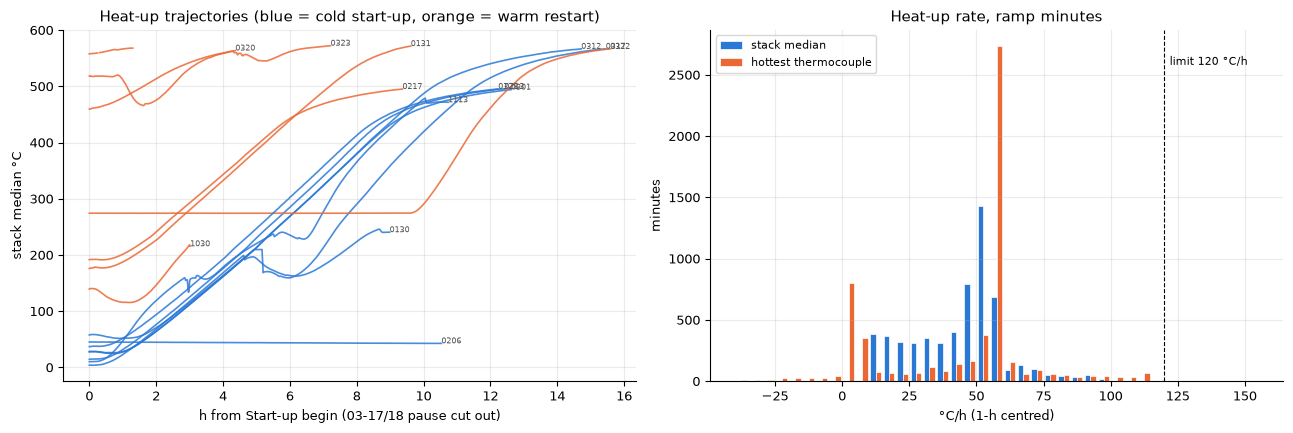

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.4))
for _, r in heat.iterrows():
    g = d[d.episode_id == r.episode_id]
    g = g[g.operation != ops.PAUSED]  # plant-off pause cut out of the clock
    h = np.arange(len(g)) / 60
    ax[0].plot(h, g.T_stack_C, color=SUB_COLORS[r.subtype], lw=1.2, alpha=0.85)
    ax[0].text(h[-1], g.T_stack_C.iloc[-1], r.episode_id[4:8], fontsize=6, color="#555")
ax[0].set_xlabel("h from Start-up begin (03-17/18 pause cut out)")
ax[0].set_ylabel("stack median °C")
ax[0].set_title("Heat-up trajectories (blue = cold start-up, orange = warm restart)")
bins = np.arange(-40, 160, 5)
ax[1].hist(
    [hu.dTdt_C_per_h.dropna(), hu.dTmaxdt_C_per_h.dropna()],
    bins=bins,
    color=["#2a78d6", "#eb6834"],
    label=["stack median", "hottest thermocouple"],
    edgecolor="white",
    linewidth=0.5,
)
ax[1].axvline(LIMIT, color="k", lw=0.8, ls="--")
ax[1].text(LIMIT + 2, ax[1].get_ylim()[1] * 0.9, "limit 120 °C/h", fontsize=8)
ax[1].set_xlabel("°C/h (1-h centred)")
ax[1].set_ylabel("minutes")
ax[1].legend(fontsize=8)
ax[1].set_title("Heat-up rate, ramp minutes")
fig.tight_layout()
fig.savefig(OUT / "heatup_rates.png", dpi=130)
plt.show()

### 4.3 Holds and pauses inside a heat-up

Stretches inside a cold start-up or warm restart where the stack is flat (|dT/dt| < 5 °C/h): the heater holds a
lower target, the plant waits, or the plant is off (*Heat-up interrupted (plant off)*). Only stretches of ≥ 30 min
are listed.

In [10]:
x = s[s.dTdt_C_per_h.abs() < ops.DTDT_STABLE].copy()
x["blk"] = (
    (x.index.to_series().diff() != pd.Timedelta("1min"))
    | (x.episode_id != x.episode_id.shift())
).cumsum()
holds = x.groupby("blk").agg(
    episode_id=("episode_id", "first"),
    start=("T_stack_C", lambda v: v.index[0]),
    minutes=("T_stack_C", "size"),
    T_stack_C=("T_stack_C", "median"),
    EAPH_target_C=("eaph_sp_C", "median"),
    EAPH_kW=("P_EAPH_kW", "median"),
    air=("air_flow", "median"),
    N2=("N2", "median"),
    operation=("operation", "first"),
)
holds = holds[holds.minutes >= 30].reset_index(drop=True)
holds.round(1).to_csv(OUT / "holds_inside_heatup.csv", index=False)
holds.round(1)

C:\Users\mrgur\AppData\Local\Temp\ipykernel_17888\1066690910.py:8: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  holds.round(1).to_csv(OUT / "holds_inside_heatup.csv", index=False)
C:\Users\mrgur\AppData\Local\Temp\ipykernel_17888\1066690910.py:9: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  holds.round(1)


,episode_id,start,minutes,T_stack_C,EAPH_target_C,EAPH_kW,air,N2,operation
0,20260206_1327_Start-up,2026-02-06 13:57:00,36,45.1,0.0,0.4,0.0,0.0,Heat-up (EAPH on)
1,20260206_1327_Start-up,2026-02-06 14:34:00,536,43.9,0.0,0.4,0.0,0.0,Heat-up (EAPH on)
2,20260301_0905_Start-up,2026-03-01 09:05:00,43,26.8,300.0,0.0,5999.3,0.0,"Air flow start (purge, heater off)"
3,20260312_1029_Start-up,2026-03-12 10:29:00,34,28.0,300.0,0.0,5999.4,0.0,"Air flow start (purge, heater off)"
4,20260317_1456_Start-up,2026-03-17 20:37:00,628,178.7,0.0,0.0,0.0,0.0,Heat-up interrupted (plant off)
5,20260322_0000_Start-up,2026-03-22 00:30:00,529,274.3,280.0,12.6,9999.9,0.0,Heat-up (EAPH on)


## 5. Heater recipe

The EAPH is controlled on its outlet temperature `TIRC_2_06` (= cathode inlet). The controller logs its target
(`ct_TIRC_206_SP_TargetValue`) and its setpoint ramp (`ct_TIRC_206_SP_SlewRateAbs`, in K/s: 0.0167 = 60 K/h,
0.0333 = 120 K/h). The table lists every target the controller was given during each heat-up, the ramp in force,
the heater energy, and how far the stack lags the heater outlet. Targets held for less than 10 min are left out.

In [11]:
rows = []
for _, r in heat.iterrows():
    g = d[d.episode_id == r.episode_id]
    sp = g.eaph_sp_C.round()
    blk = (sp != sp.shift()).cumsum()
    held = sp.groupby(blk).agg(["first", "size"])
    held = held[(held["size"] >= 10) & (held["first"] > 0)]["first"]
    steps = held[held != held.shift()]
    on = g.P_EAPH_kW > ops.EAPH_ON_W / 1000
    rows.append(
        {
            "episode_id": r.episode_id,
            "subtype": r.subtype,
            "setpoint_steps_C": " → ".join(f"{v:.0f}" for v in steps.values),
            "ramp_K_per_h": round(g.eaph_sp_slew[on].round(4).mode().iat[0] * 3600)
            if on.any()
            else np.nan,
            "EAPH_out_rate_C_per_h": (
                g.TIRC_2_06.asfreq("1min").diff(60)[on.asfreq("1min", fill_value=False)]
            ).median(),
            "EAPH_max_kW": g.P_EAPH_kW.max(),
            "EAPH_mean_kW_when_on": g.P_EAPH_kW[on].mean(),
            "EAPH_energy_kWh": g.P_EAPH_kW.sum() / 60,
            "kWh_per_100K": g.P_EAPH_kW.sum()
            / 60
            / max(r.T_end_C - r.T_start_C, 1)
            * 100,
            "stack_lag_K_median": (g.TIRC_2_06 - g.T_stack_C)[on].median(),
            "stack_lag_K_max": (g.TIRC_2_06 - g.T_stack_C)[on].max(),
        }
    )
rec = pd.DataFrame(rows).set_index("episode_id")
rec.round(1).to_csv(OUT / "heater_recipe.csv")
rec.round(1)

,subtype,setpoint_steps_C,ramp_K_per_h,EAPH_out_rate_C_per_h,EAPH_max_kW,EAPH_mean_kW_when_on,EAPH_energy_kWh,kWh_per_100K,stack_lag_K_median,stack_lag_K_max
episode_id,,,,,,,,,,
20251030_1129_Start-up,Warm restart,600,120,84.5,18.5,12.2,25.3,33.3,81.3,89.6
20251113_1047_Start-up,Cold start-up,300 → 600 → 450,120,59.2,28.9,17.6,159.9,34.6,71.2,138.2
20260130_1010_Start-up,Cold start-up,300 → 259 → 300 → 280 → 50,60,59.7,18.0,10.2,81.0,34.3,53.5,80.0
20260131_0809_Start-up,Warm restart,300 → 600 → 500,60,58.8,33.2,21.6,208.5,52.7,72.7,102.7
20260206_1327_Start-up,Cold start-up,,1224,-0.2,0.4,0.4,4.3,428.0,-1.2,-0.9
20260213_1432_Start-up,Cold start-up,300 → 600 → 500,60,59.1,27.5,17.0,210.8,43.8,64.1,96.9
20260217_1656_Start-up,Warm restart,300 → 600 → 500,60,56.3,26.4,17.0,159.5,52.5,54.7,93.6
20260301_0905_Start-up,Cold start-up,300 → 500,60,58.9,27.7,17.0,207.1,44.4,64.6,98.7
20260312_1029_Start-up,Cold start-up,300 → 500 → 570,60,59.0,31.3,18.5,264.0,49.0,66.6,104.7


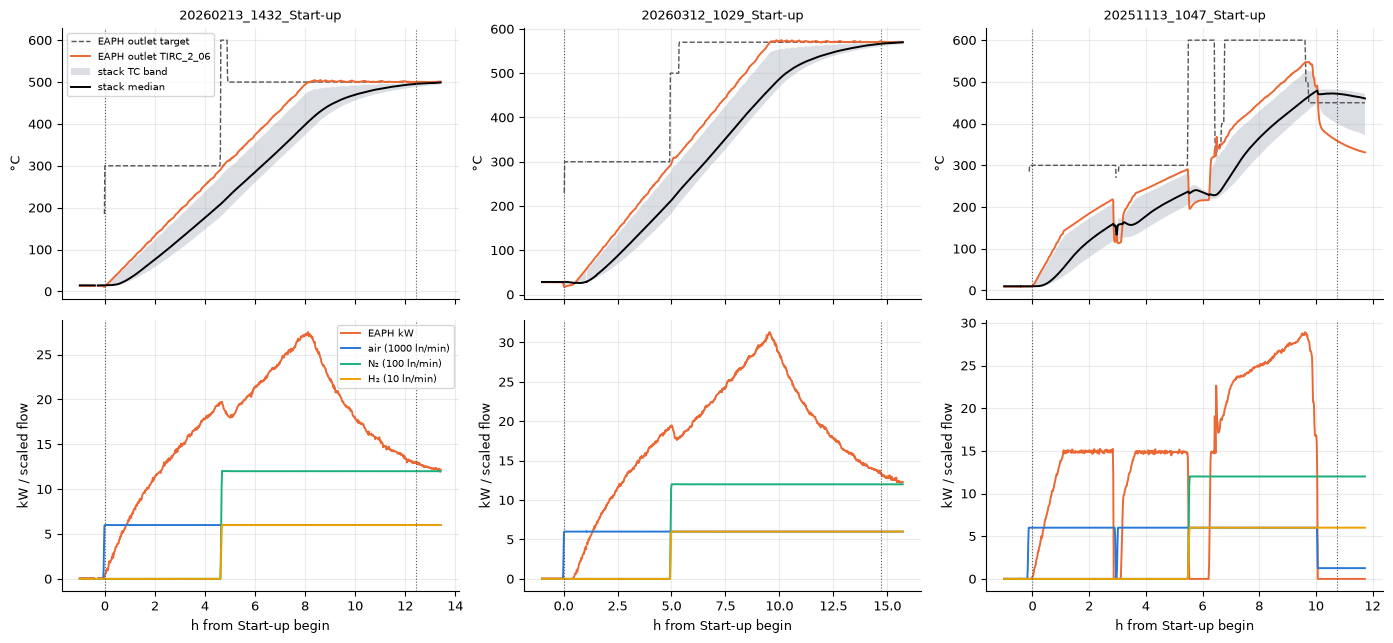

In [12]:
pick = [
    i
    for i in (
        "20260213_1432_Start-up",
        "20260312_1029_Start-up",
        "20251113_1047_Start-up",
    )
    if i in set(heat.episode_id)
]
fig, axs = plt.subplots(2, len(pick), figsize=(14, 6.5), sharex="col")
for j, eid in enumerate(pick):
    g = d[d.episode_id == eid]
    w = d.loc[g.index[0] - pd.Timedelta("1h") : g.index[-1] + pd.Timedelta("1h")]
    h = (w.index - g.index[0]).total_seconds() / 3600
    a = axs[0, j]
    a.plot(
        h,
        w.eaph_sp_C.where(w.eaph_sp_C > 0),
        color="#555",
        lw=1,
        ls="--",
        label="EAPH outlet target",
    )
    a.plot(h, w.TIRC_2_06, color="#eb6834", label="EAPH outlet TIRC_2_06")
    a.fill_between(
        h,
        w.T_tc_min_C,
        w.T_tc_max_C,
        color="#9aa5b1",
        alpha=0.35,
        lw=0,
        label="stack TC band",
    )
    a.plot(h, w.T_stack_C, color="k", label="stack median")
    a.set_title(eid, fontsize=9)
    a.set_ylabel("°C")
    b = axs[1, j]
    b.plot(h, w.P_EAPH_kW, color="#eb6834", label="EAPH kW")
    b.plot(h, w.air_flow / 1000, color="#2a78d6", label="air (1000 ln/min)")
    b.plot(h, w.N2 / 100, color="#1baf7a", label="N₂ (100 ln/min)")
    b.plot(h, w.H2 / 10, color="#eda100", label="H₂ (10 ln/min)")
    b.set_xlabel("h from Start-up begin")
    b.set_ylabel("kW / scaled flow")
    for x in axs[:, j]:
        x.axvline(0, color="#555", lw=0.8, ls=":")
        x.axvline(
            (g.index[-1] - g.index[0]).total_seconds() / 3600,
            color="#555",
            lw=0.8,
            ls=":",
        )
axs[0, 0].legend(fontsize=7)
axs[1, 0].legend(fontsize=7)
fig.tight_layout()
fig.savefig(OUT / "recipe_examples.png", dpi=130)
plt.show()

The lower panels put the flows on one scaled axis (air in 1000 ln/min, N₂ in 100 ln/min, H₂ in 10 ln/min) only to
show the order of switching; the levels are in §7 and §9. Dotted lines mark the episode begin and end.

**Heater power against stack temperature.** With the outlet following a fixed ramp, the heater power needed grows
with the stack temperature (more heat lost through the insulation and carried out by the air). A linear fit over the
ramp minutes of cold start-ups and warm restarts:

In [13]:
x = s[ramp & (s.P_EAPH_kW > ops.EAPH_ON_W / 1000)]
x = x[["T_stack_C", "P_EAPH_kW", "air_flow"]].dropna()
p_slope, c0 = np.polyfit(x.T_stack_C, x.P_EAPH_kW, 1)
r2 = np.corrcoef(x.T_stack_C, x.P_EAPH_kW)[0, 1] ** 2
print(
    f"P_EAPH ≈ {c0:.1f} kW + {p_slope * 100:.2f} kW per 100 K of stack temperature "
    f"(R² {r2:.2f}, {len(x):,} minutes)"
)
tb = x.groupby(pd.cut(x.T_stack_C, np.arange(0, 651, 50))).P_EAPH_kW.describe()[
    ["count", "25%", "50%", "75%"]
]
tb.round(1)

P_EAPH ≈ 8.9 kW + 3.33 kW per 100 K of stack temperature (R² 0.51, 5,883 minutes)


,count,25%,50%,75%
T_stack_C,,,,
"(0, 50]",342.0,4.3,5.8,7.4
"(50, 100]",449.0,8.8,10.3,11.7
"(100, 150]",471.0,13.1,14.1,15.0
"(150, 200]",682.0,12.5,16.2,17.3
"(200, 250]",572.0,14.4,16.2,18.4
"(250, 300]",449.0,17.7,19.7,20.8
"(300, 350]",446.0,21.9,23.2,24.0
"(350, 400]",450.0,25.0,25.5,26.5
"(400, 450]",527.0,24.1,26.7,27.9


## 6. Thermal gradient across the stack

During a heat-up the warm air enters on one side, so the thermocouples near the cathode inlet lead. `spread` is the
hottest minus the coldest valid thermocouple; `inlet lead` is the mean of `TIR_4_6_1…8` minus the mean of the
others (that group sits ~10 K *below* the rest in Hot standby, so a lead of +60 K is a 70 K swing).

In [14]:
grad = (
    s.groupby("episode_id")
    .agg(
        subtype=("subtype", "first"),
        spread_median_K=("T_spread_K", "median"),
        spread_max_K=("T_spread_K", "max"),
        inlet_lead_median_K=("T_inlet_lead_K", "median"),
        inlet_lead_max_K=("T_inlet_lead_K", "max"),
    )
    .loc[su.episode_id]
)
grad.round(1).to_csv(OUT / "thermal_gradient.csv")
hs = d[d.stage == "Hot standby"]
print(
    f"reference, Hot standby: spread median {hs.T_spread_K.median():.0f} K, inlet "
    f"lead median {hs.T_inlet_lead_K.median():.0f} K"
)
grad.round(1)

reference, Hot standby: spread median 15 K, inlet lead median -11 K


,subtype,spread_median_K,spread_max_K,inlet_lead_median_K,inlet_lead_max_K
episode_id,,,,,
20251030_1129_Start-up,Warm restart,51.2,101.9,40.9,71.7
20251113_1047_Start-up,Cold start-up,86.5,118.0,53.7,101.9
20260130_1010_Start-up,Cold start-up,54.0,93.3,41.3,64.8
20260131_0809_Start-up,Warm restart,74.2,95.5,56.3,76.5
20260206_1327_Start-up,Cold start-up,3.5,3.8,-0.2,-0.1
20260213_1432_Start-up,Cold start-up,72.7,98.4,52.2,73.5
20260217_1656_Start-up,Warm restart,55.1,91.0,43.2,71.0
20260301_0905_Start-up,Cold start-up,70.8,101.5,51.3,77.1
20260312_1029_Start-up,Cold start-up,74.9,101.8,54.2,80.1


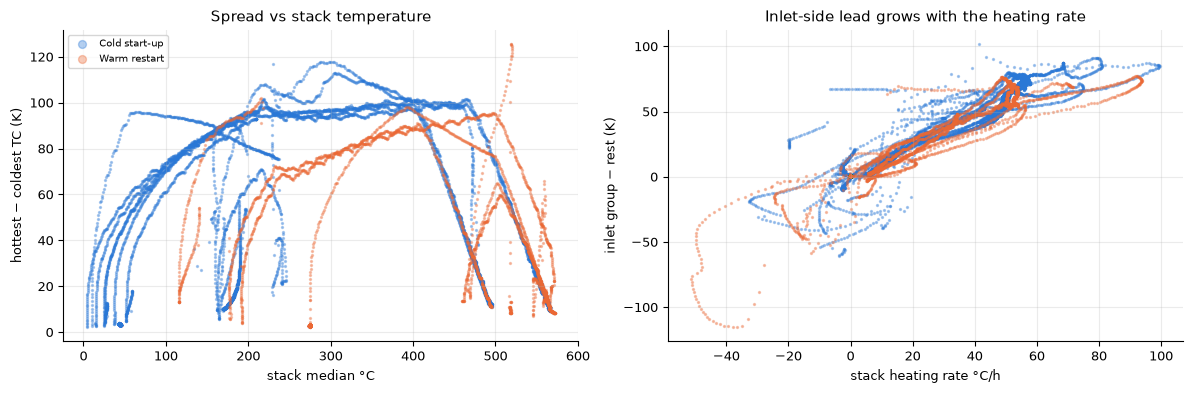

inlet lead ≈ 1.14 K per °C/h of heating rate (R² 0.87)


In [15]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for n, col in SUB_COLORS.items():
    xx = s[s.subtype == n]
    ax[0].scatter(xx.T_stack_C, xx.T_spread_K, s=2, color=col, alpha=0.35, label=n)
    ax[1].scatter(
        xx.dTdt_C_per_h, xx.T_inlet_lead_K, s=2, color=col, alpha=0.35, label=n
    )
ax[0].set_xlabel("stack median °C")
ax[0].set_ylabel("hottest − coldest TC (K)")
ax[0].set_title("Spread vs stack temperature")
ax[1].set_xlabel("stack heating rate °C/h")
ax[1].set_ylabel("inlet group − rest (K)")
ax[1].set_title("Inlet-side lead grows with the heating rate")
ax[0].legend(fontsize=7, markerscale=4)
fig.tight_layout()
fig.savefig(OUT / "thermal_gradient.png", dpi=130)
plt.show()
xx = s[["dTdt_C_per_h", "T_inlet_lead_K"]].dropna()
print(
    f"inlet lead ≈ {np.polyfit(xx.dTdt_C_per_h, xx.T_inlet_lead_K, 1)[0]:.2f} K per "
    "°C/h of heating rate "
    f"(R² {np.corrcoef(xx.dTdt_C_per_h, xx.T_inlet_lead_K)[0, 1] ** 2:.2f})"
)

## 7. Gas and air sequence during a heat-up

For each cold start-up and warm restart: the first minute each signal is on, relative to the first Start-up minute
(negative = before), and the stack and EAPH-outlet temperature at that moment. `on at start` = already on when the
episode begins (e.g. air still on after a cool-down).

| Signal | On when |
|---|---|
| Air flow (FIRC 1.1.1 + 1.1.2) | > 50 ln/min |
| EAPH heater | > 0.2 kW |
| N₂ (FIRC 1.3) / H₂ (FIRC 1.5), forming gas | > 1 / > 0.5 ln/min |
| Natural gas (FIRC 1.4) | > 5 ln/min |

In [16]:
ON = {
    "air": lambda w: w.air_flow > 50,
    "EAPH": lambda w: w.P_EAPH_kW > ops.EAPH_ON_W / 1000,
    "N2": lambda w: w.N2 > 1,
    "H2": lambda w: w.H2 > 0.5,
    "NG": lambda w: w.fuel > 5,
}
rows = []
for _, r in heat.iterrows():
    g = d[d.episode_id == r.episode_id]
    w = d.loc[g.index[0] - pd.Timedelta("3h") : g.index[-1]]
    t0 = g.index[0]
    row = {
        "episode_id": r.episode_id,
        "subtype": r.subtype,
        "T_start_C": round(r.T_start_C, 0),
    }
    for k, f in ON.items():
        on = f(w)
        sw = on.index[
            on & ~on.shift(fill_value=on.iloc[0])
        ]  # off → on switches in the window
        if on.loc[t0] and not (sw <= t0).any():
            row[f"{k}_min"] = "on at start"
            continue
        row[f"{k}_min"] = (
            round((sw[0] - t0).total_seconds() / 60) if len(sw) else np.nan
        )
        if k in ("N2", "NG") and len(sw):
            row[f"T_stack_at_{k}_C"] = round(w.T_stack_C.asof(sw[0]), 0)
            row[f"T_EAPH_out_at_{k}_C"] = round(w.TIRC_2_06.asof(sw[0]), 0)
    row["air_flow_median"] = round(g.air_flow[g.air_flow > 50].median(), 0)
    row["N2_median"] = round(g.N2[g.N2 > 1].median(), 0) if (g.N2 > 1).any() else np.nan
    row["H2_median"] = (
        round(g.H2[g.H2 > 0.5].median(), 1) if (g.H2 > 0.5).any() else np.nan
    )
    rows.append(row)
seq = pd.DataFrame(rows).set_index("episode_id")
seq.to_csv(OUT / "gas_sequence.csv")
seq

,subtype,T_start_C,air_min,EAPH_min,N2_min,T_stack_at_N2_C,T_EAPH_out_at_N2_C,H2_min,NG_min,air_flow_median,N2_median,H2_median
episode_id,,,,,,,,,,,,
20251030_1129_Start-up,Warm restart,139.0,-1,58,169,205.0,287.0,169,NaN,6000.0,1200.0,60.0
20251113_1047_Start-up,Cold start-up,10.0,-10,0,329,237.0,290.0,329,NaN,6000.0,1200.0,60.0
20260130_1010_Start-up,Cold start-up,4.0,-10,0,NaN,NaN,NaN,NaN,NaN,6000.0,NaN,NaN
20260131_0809_Start-up,Warm restart,176.0,-2,0,119,226.0,290.0,119,NaN,6000.0,1200.0,60.0
20260206_1327_Start-up,Cold start-up,45.0,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
20260213_1432_Start-up,Cold start-up,15.0,-3,0,277,208.0,290.0,278,NaN,6000.0,1200.0,60.0
20260217_1656_Start-up,Warm restart,192.0,-30,-28,106,230.0,291.0,106,NaN,6000.0,1200.0,60.0
20260301_0905_Start-up,Cold start-up,28.0,-1,27,297,210.0,292.0,297,NaN,6000.0,1200.0,60.0
20260312_1029_Start-up,Cold start-up,28.0,-1,29,296,210.0,291.0,296,NaN,6000.0,1200.0,60.0


In [17]:
num = seq.apply(pd.to_numeric, errors="coerce")
print("medians over the episodes where the switch is seen:")
print(
    num[
        [
            "air_min",
            "EAPH_min",
            "N2_min",
            "H2_min",
            "T_stack_at_N2_C",
            "T_EAPH_out_at_N2_C",
        ]
    ]
    .median()
    .round(0)
    .to_string()
)

medians over the episodes where the switch is seen:
air_min                -2.0
EAPH_min                0.0
N2_min                277.0
H2_min                278.0
T_stack_at_N2_C       210.0
T_EAPH_out_at_N2_C    291.0


**Does the forming gas follow the EAPH outlet or the stack?** If the trigger is the EAPH outlet reaching its first
target (300 °C), the outlet temperature at the N₂ switch-on is tight and the stack temperature varies; the reverse
points to a stack-temperature trigger. Only start-ups that begin below 200 °C (the others switch at a restart, not
on the way up).

In [18]:
z = num[num.T_start_C < 200][["T_stack_at_N2_C", "T_EAPH_out_at_N2_C"]].dropna()
z.describe().loc[["count", "mean", "std", "min", "max"]].round(1)

,T_stack_at_N2_C,T_EAPH_out_at_N2_C
count,9.0,9.0
mean,214.2,288.3
std,14.0,5.9
min,192.0,273.0
max,237.0,292.0


## 8. Timings

Durations per sub-type, and the clock time a cold start-up or warm restart begins and ends. `heating_h` is the
duration without the 11 h plant-off pause of 2026-03-17/18; the duration statistics use it.

In [19]:
dur = su.groupby("subtype").heating_h.describe()[["count", "min", "50%", "max"]]
dur["total_h"] = su.groupby("subtype").heating_h.sum()
dur["pause_h"] = su.groupby("subtype").pause_h.sum()
print(dur.round(2).to_string())
full = su[su.outcome.str.startswith("reached")]
for n, g in full.groupby("subtype"):
    print(
        f"{n} that reached Hot standby: {len(g)}, heating time "
        f"{g.heating_h.min():.1f}–{g.heating_h.max():.1f} h "
        f"(median {g.heating_h.median():.1f} h)"
    )
tm = heat[
    [
        "episode_id",
        "subtype",
        "start",
        "end",
        "duration_h",
        "pause_h",
        "heating_h",
        "outcome",
    ]
].assign(
    begin_clock=heat.start.dt.strftime("%H:%M"), end_clock=heat.end.dt.strftime("%H:%M")
)
tm.to_csv(OUT / "timings.csv", index=False)
tm

               count   min    50%    max  total_h  pause_h
subtype                                                   
Cold start-up    8.0  9.00  12.34  15.47    97.81    11.05
Warm restart     7.0  1.33   7.23  15.60    50.58     0.00
Cold start-up that reached Hot standby: 5, heating time 12.2–15.5 h (median 12.6 h)
Warm restart that reached Hot standby: 5, heating time 1.3–15.6 h (median 9.4 h)


,episode_id,subtype,start,end,duration_h,pause_h,heating_h,outcome,begin_clock,end_clock
1,20251030_1129_Start-up,Warm restart,2025-10-30 11:29:00,2025-10-30 14:31:00,3.03,0.00,3.03,stopped → Idle,11:29,14:31
4,20251113_1047_Start-up,Cold start-up,2025-11-13 10:47:00,2025-11-13 21:32:00,10.75,0.00,10.75,stopped → Shut-down,10:47,21:32
7,20260130_1010_Start-up,Cold start-up,2026-01-30 10:10:00,2026-01-30 19:10:00,9.00,0.00,9.00,stopped → Shut-down,10:10,19:10
9,20260131_0809_Start-up,Warm restart,2026-01-31 08:09:00,2026-01-31 17:47:00,9.63,0.00,9.63,reached Hot standby,08:09,17:47
16,20260206_1327_Start-up,Cold start-up,2026-02-06 13:27:00,2026-02-07 00:00:00,10.55,0.00,10.55,cut at file edge,13:27,00:00
18,20260213_1432_Start-up,Cold start-up,2026-02-13 14:32:00,2026-02-14 02:58:00,12.43,0.00,12.43,reached Hot standby,14:32,02:58
21,20260217_1656_Start-up,Warm restart,2026-02-17 16:56:00,2026-02-18 02:19:00,9.38,0.00,9.38,reached Hot standby,16:56,02:19
27,20260301_0905_Start-up,Cold start-up,2026-03-01 09:05:00,2026-03-01 21:43:00,12.63,0.00,12.63,reached Hot standby,09:05,21:43
37,20260312_1029_Start-up,Cold start-up,2026-03-12 10:29:00,2026-03-13 01:13:00,14.73,0.00,14.73,reached Hot standby,10:29,01:13
45,20260317_1456_Start-up,Cold start-up,2026-03-17 14:56:00,2026-03-18 17:27:00,26.52,11.05,15.47,reached Hot standby,14:56,17:27


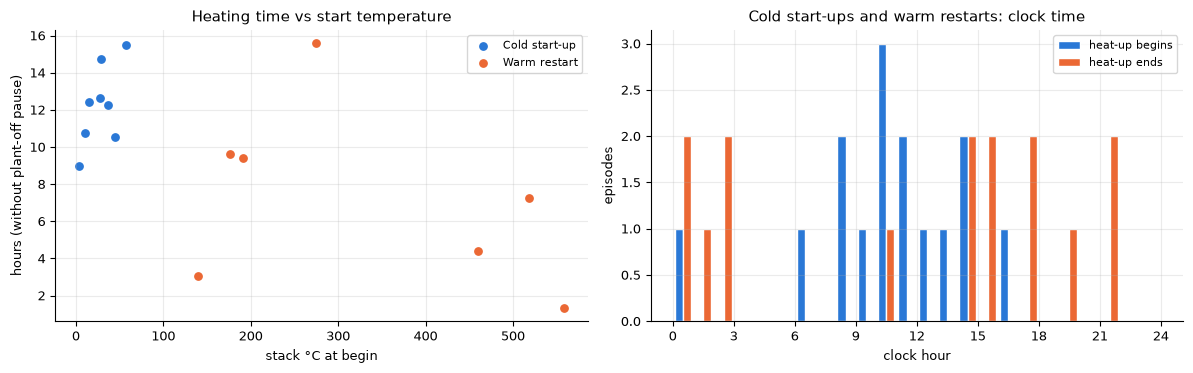

In [20]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for n, col in SUB_COLORS.items():
    xx = su[su.subtype == n]
    ax[0].scatter(xx.T_start_C, xx.heating_h, color=col, label=n, s=28)
ax[0].set_xlabel("stack °C at begin")
ax[0].set_ylabel("hours (without plant-off pause)")
ax[0].set_title("Heating time vs start temperature")
ax[0].legend(fontsize=8)
hb = np.arange(0, 25, 1)
ax[1].hist(
    [
        heat.start.dt.hour + heat.start.dt.minute / 60,
        heat.end.dt.hour + heat.end.dt.minute / 60,
    ],
    bins=hb,
    color=["#2a78d6", "#eb6834"],
    label=["heat-up begins", "heat-up ends"],
    edgecolor="white",
)
ax[1].set_xticks(range(0, 25, 3))
ax[1].set_xlabel("clock hour")
ax[1].set_ylabel("episodes")
ax[1].set_title("Cold start-ups and warm restarts: clock time")
ax[1].legend(fontsize=8)
fig.tight_layout()
fig.savefig(OUT / "timings.png", dpi=130)
plt.show()

## 9. Signal levels by temperature band

Median levels of the main signals during the ramp minutes of cold start-ups and warm restarts (plus all their
minutes above 450 °C, where the approach to Hot standby is slow), per 50 K band of the stack median: the
lookup a synthetic heat-up generator needs (together with the ramp in §5). Noise σ is the robust standard deviation
of the 1-min first difference / √2, as in the plant-off notebook.

In [21]:
x = s[ramp | (s.T_stack_C > 450)]
LEV = {
    "EAPH kW": "P_EAPH_kW",
    "EAPH outlet °C": "TIRC_2_06",
    "EAPH target °C": "eaph_sp_C",
    "air ln/min": "air_flow",
    "N2 ln/min": "N2",
    "H2 ln/min": "H2",
    "PIR_2_02": "P_air_in",
    "TC spread K": "T_spread_K",
    "inlet lead K": "T_inlet_lead_K",
    "afterburner TIRC_5_09 °C": "TIRC_5_09",
    "reformer in TIRC_3_07 °C": "TIRC_3_07",
    "roof exhaust TIR_7_05 °C": "TIR_7_05",
    "heat-up rate °C/h": "dTdt_C_per_h",
}
lev = x.groupby(pd.cut(x.T_stack_C, np.arange(0, 651, 50)))[list(LEV.values())].median()
lev.columns = list(LEV)
lev.insert(0, "minutes", x.groupby(pd.cut(x.T_stack_C, np.arange(0, 651, 50))).size())
lev.round(1).to_csv(OUT / "levels_by_band.csv")
lev.round(1)

,minutes,EAPH kW,EAPH outlet °C,EAPH target °C,air ln/min,N2 ln/min,H2 ln/min,PIR_2_02,TC spread K,inlet lead K,afterburner TIRC_5_09 °C,reformer in TIRC_3_07 °C,roof exhaust TIR_7_05 °C,heat-up rate °C/h
T_stack_C,,,,,,,,,,,,,,
"(0, 50]",342,5.8,68.6,300.0,5999.9,0.0,0.0,3.4,36.4,31.3,28.3,22.9,17.9,29.8
"(50, 100]",449,10.3,130.0,300.0,6000.0,0.0,0.0,3.7,60.9,46.3,65.3,54.0,20.5,46.0
"(100, 150]",474,14.1,191.2,300.0,6000.0,0.0,0.0,4.2,78.3,55.5,112.5,93.5,23.4,49.5
"(150, 200]",695,16.1,243.4,300.0,6000.0,0.0,0.0,4.7,86.6,61.4,163.5,142.9,27.9,48.9
"(200, 250]",572,16.2,293.2,500.0,6000.0,1198.1,60.0,7.7,92.2,66.9,235.8,77.9,34.6,49.8
"(250, 300]",449,19.7,357.9,570.0,6000.1,1200.0,60.0,8.7,94.1,69.5,279.0,51.1,54.5,54.2
"(300, 350]",446,23.2,414.6,570.0,6000.1,1200.0,60.0,9.3,95.3,71.8,314.7,53.8,61.6,55.7
"(350, 400]",450,25.5,466.8,570.0,6000.0,1200.0,60.0,10.0,98.0,73.3,352.1,61.0,69.4,56.2
"(400, 450]",527,26.7,502.5,500.0,6000.0,1200.0,60.0,10.8,90.1,66.5,392.8,71.1,78.4,52.5


In [22]:
noise = pd.Series(
    {k: ss.robust_sigma(x[c]) for k, c in LEV.items()}, name="noise_sigma_per_min"
)
noise.round(3).to_frame()

,noise_sigma_per_min
EAPH kW,0.107
EAPH outlet °C,0.518
EAPH target °C,0.000
air ln/min,0.650
N2 ln/min,0.070
H2 ln/min,0.000
PIR_2_02,0.017
TC spread K,0.298
inlet lead K,0.240
afterburner TIRC_5_09 °C,0.206


## 10. Summary

In [23]:
summary = pd.Series(
    {
        "Start-up minutes": (
            f"{len(s):,} ({len(s) / 60:.0f} h, {len(s) / len(d):.0%} of logged time)"
        ),
        "Episodes": ", ".join(f"{n} {k}" for k, n in su.subtype.value_counts().items()),
        "Reached Hot standby or load": (
            f"{su.outcome.str.startswith('reached').sum()} of {len(su)}"
        ),
        "Cold start-up to Hot standby, heating time": (
            lambda g: (
                f"{g.heating_h.min():.1f}–{g.heating_h.max():.1f} h "
                f"(median {g.heating_h.median():.1f} h), plus {su.pause_h.sum():.1f} "
                "h plant-off pause on 03-17/18"
            )
        )(su[(su.subtype == "Cold start-up") & su.outcome.str.startswith("reached")]),
        "Ramp rate, median / p95 (stack median)": (
            f"{hu.dTdt_C_per_h.median():.0f} / "
            f"{hu.dTdt_C_per_h.quantile(0.95):.0f} °C/h"
        ),
        "Ramp rate, hottest TC p95 / max": (
            f"{hu.dTmaxdt_C_per_h.quantile(0.95):.0f} / "
            f"{hu.dTmaxdt_C_per_h.max():.0f} °C/h"
        ),
        "EAPH power vs stack T": f"{c0:.1f} kW + {p_slope * 100:.2f} kW per 100 K",
        "Forming gas on at (median)": (
            f"stack {num.T_stack_at_N2_C.median():.0f} °C, EAPH outlet "
            f"{num.T_EAPH_out_at_N2_C.median():.0f} °C"
        ),
    },
    name="value",
)
summary.to_frame()

,value
Start-up minutes,"9,568 (159 h, 17% of logged time)"
Episodes,"8 Cold start-up, 7 Warm restart"
Reached Hot standby or load,10 of 15
"Cold start-up to Hot standby, heating time","12.2–15.5 h (median 12.6 h), plus 11.1 h plant..."
"Ramp rate, median / p95 (stack median)",49 / 70 °C/h
"Ramp rate, hottest TC p95 / max",83 / 150 °C/h
EAPH power vs stack T,8.9 kW + 3.33 kW per 100 K
Forming gas on at (median),"stack 210 °C, EAPH outlet 291 °C"


### Findings

**How much and what kind**
- Start-up covers **159 h (17 %)** of the 39 logged days in **15 episodes**: 8 cold start-ups and 7 warm restarts.
  10 of the 15 reach Hot standby. Re-heats and cool-backs of a hot stack are not counted here: they are the stage
  Thermal adjustment (`thermal_adjustment_analysis.ipynb`).
- Of the 8 cold start-ups, **5 reach Hot standby**: 02-13, 03-01 and 03-28 at ~495 °C in **12.2–12.6 h**; 03-12
  straight to 567 °C in 14.7 h; and **03-17/18** to 567 °C in 15.5 h of heating plus the **11.1 h plant-off pause**
  (26.5 h in all). Two stop early and cool down (Start-up → Shut-down, not in the design): 2025-11-13 at 472 °C and
  2026-01-30 at 240 °C. The eighth, **2026-02-06**, is not a real start-up: no air, no warming, heater reading
  0.4 kW for 10.5 h (see Open points).
- Warm restarts: 01-31 (176 °C) and 02-17 (192 °C) take **9.4–9.6 h** to the hold; 03-22 from the ~274 °C park
  takes 15.6 h (9 h of it still parked); 03-20 restarts from 460 °C after a cool-down (4.4 h + 1.3 h, split by a
  2 h logger gap); 03-23 starts at 518 °C after a 9.6 h logger gap (see Open points). 2025-10-30 (139 → 216 °C, 3 h,
  first file) stops into Idle (not in the design).

**Heat-up rate (§4)**
- The stack median warms at **~50 °C/h** between 50 and 500 °C (band medians 47 / 50 / 55 / 57 / 52 °C/h), then
  slows to **21–40 °C/h** (median 29) from 500 to 550 °C as it approaches the target. Over all 5 900 ramp minutes:
  median 49 °C/h, p95 70 °C/h. The stack median never exceeds 100 °C/h.
- Hottest thermocouple: p95 83 °C/h. It goes above the **120 °C/h limit only on 2025-11-13** (18 min, max
  150 °C/h). Every start-up since February stays below 63 °C/h on the hottest point, except 03-18 right after the
  restart (113 °C/h at 08:26, stack ~190 °C) and the 120 K/h ramps of 03-22 (114 °C/h) and 03-23 (84 °C/h).

**Heater recipe (§5)**
- The EAPH outlet `TIRC_2_06` follows a **setpoint ramp of 60 K/h** (`SP_SlewRateAbs` = 0.0167 K/s) to a first
  target of **300 °C**. The outlet tracks it at 56–60 °C/h and the stack follows **54–73 K behind** (median per heat-up from below 200 °C,
  up to 80–138 K).
- When the outlet reaches ~290 °C, forming gas comes on and the target is raised: to **500 °C** (February via a short
  600 °C step, 03-01, 03-28: the ~500 °C hold) or to **570–590 °C** (03-12 via 500 °C, 03-17, and again after the
  03-18 restart: straight to Hot standby).
- Early runs (2025-10-30, 11-13) and the late-March restarts (03-22, 03-23) use a **120 K/h** ramp. On 03-22 that
  gives 61 °C/h median and 93 °C/h p95 at the stack, with 10 000 ln/min air and up to 41 kW heater power.
- Heater power at 6 000 ln/min air rises from **~6 kW** below 50 °C to **~27 kW** at 400–450 °C, then falls as the
  stack closes in on the target. A full cold start-up to ~495 °C uses **202–211 kWh** (about 44 kWh per 100 K),
  264 kWh to 567 °C (03-12) and 245 kWh on 03-17/18 (heater off during the pause).

**Holds and pauses (§4.3)**
- 2026-03-17/18 **plant-off pause**: air, gas and heater off from 20:08 to 07:10 next morning; the stack drifts
  from 188 to 167 °C (≈ −2 °C/h). On restart the outlet target goes back to 300 °C, forming gas returns at ~09:00
  and the stack reaches Hot standby (567 °C) at 17:27. The pause is kept out of the rate statistics, and the
  200→300 °C band of this episode is blanked.
- 2026-03-22: the stack is held flat at **274 °C for ~9 h** (target 280 °C, 10 000 ln/min air, no forming gas). The
  file of 03-21 is missing, but the 03-20 evening cool-down ends with the heater holding 280 °C
  (`shutdown_analysis.ipynb` §10), so the plant was most likely parked at ~280 °C from 03-20 to 03-22. The 120 K/h
  ramp to 570 °C follows at 09:30.
- 03-01 and 03-12 purge with air for 34–43 min before the heater comes on.

**Thermal gradient (§6)**
- During a cold heat-up the thermocouple spread is **54–87 K** (median per episode), peaking at ~93–118 K, against
  15 K in Hot standby (03-17/18 shows a median of only 26 K because the 11 h pause is inside). The inlet-side group
  `TIR_4_6_1…8` leads the rest by **+41 to +54 K** (median per episode), while in Hot standby it sits 11 K below. The lead scales
  with the heating rate: **≈ 1.1 K per °C/h** (R² 0.87).

**Gas and air sequence (§7)**
1. **Air** (6 000 ln/min) first, a median of **2 min** before the first Start-up minute (1–35 min; 03-23: 4 min after).
2. **EAPH** at minute 0, or 27–58 min later after an air purge.
3. **Forming gas N₂ 1 200 + H₂ 60 ln/min**, both in the same minute, **~4.6 h** in, at a stack temperature of
   **192–237 °C (median 210 °C)**. The trigger is the EAPH outlet reaching its 300 °C target: the outlet reads
   **273–292 °C** at the switch (σ 6 K), while the stack varies by σ 14 K.
4. No natural gas at any point of a Start-up. The switch to natural gas before load happens later, in Hot standby
   *Pre-load* or a Thermal adjustment.

**Timings (§8)**
- Cold start-ups begin between **09:05 and 14:56**, warm restarts between 06:30 and 16:56. With 12–15 h of heating,
  a cold start-up reaches Hot standby **between 21:43 and 02:58** (03-17/18: 17:27 the next day, because of the
  pause).

### For the synthetic-data generator
| Parameter | Value |
|---|---|
| EAPH outlet target | ramp 60 K/h (120 K/h variant) to 300 °C → at outlet ≈ 290 °C step to 500 °C (hold) or 570 °C |
| Stack response | ≈ 50 °C/h from 50 to 500 °C, 54–73 K below the outlet; slows to 21–40 °C/h above 500 °C |
| Heater power | ≈ 6 kW at start, rising to ~27 kW at 400–450 °C (6 000 ln/min air); ≈ 44 kWh per 100 K |
| Air | 6 000 ln/min (10 000 in late March), on ~2 min before the heater; PIR_2_02 3.4 → 12.5 as the stack warms |
| Forming gas | N₂ 1 200 + H₂ 60 ln/min, step on at stack ≈ 210 °C (outlet ≈ 290 °C), stays on to Hot standby |
| Thermal gradient | inlet lead ≈ 1.1 K × heating rate (°C/h); spread up to ~100 K during the ramp, 15 K at the hold |
| Plant-off pause (optional) | all off, stack drifts ≈ −2 °C/h; restart repeats the 300 °C target and the forming-gas step |
| Clock time | cold start begins 09:00–15:00 |

### Open points
1. **2026-02-06 false start**: labelled *Heat-up (EAPH on)* for 10.5 h because the EAPH reads 0.4 kW, above the
   `EAPH_ON_W` = 200 W threshold, with no air and no warming. Raise the threshold (e.g. 1 kW), or require air flow
   for a heat-up?
2. **2026-03-22 warm hold at 274 °C (9 h)**: it stays a Start-up (below 450 °C, so not Hot standby). Keep it as a
   heat-up, or give it its own operation (e.g. *Warm hold*)?
3. **Logger dropouts**: `operating_states.py` does not blank the dropout minutes, so its rates show false spikes
   (2026-03-13, 03-23). Blank them there too?
4. **120 K/h ramp**: confirm with the operator why the ramp setting changed on 03-22 / 03-23, and whether 120 K/h is
   an allowed recipe for the generator.
5. **2026-03-23 Start-up after Hot standby**: it begins at 518 °C right after a 9.6 h logger gap that follows a Hot
   standby (03-22 23:04 → 03-23 08:40). Hot standby → Start-up is not in the design; the stack is hot, so it looks
   like a Thermal adjustment re-heat whose context was lost in the gap. Relabel it?